# Proyecto Integrador: Dinámica de Producción y Demanda de Gas Natural en Argentina (1996 - 2026)
## 1. Objetivo General

Analizar de manera integral la evolución histórica de la producción y la matriz de demanda de gas natural en Argentina durante el período 1996–2026, caracterizando los patrones estacionales por tipo de usuario y por licenciataria de distribución, con el fin de desarrollar modelos supervisados de predicción de consumo y modelos no supervisados de segmentación operativa regional.

# 2. Objetivos Específicos
**Evaluar el balance de gas:** Cuantificar la relación histórica entre producción nacional y volumen total entregado a usuarios finales, identificando brechas estacionales críticas de abastecimiento.

**Describir la matriz por tipo de usuario:** Identificar la estructura de la demanda (industrias, centrales eléctricas) y medir cuantitativamente la volatilidad del pico invernal residencial.

**Caracterizar el perfil geográfico:** Determinar el grado de concentración del consumo en las principales distribuidoras (AMBA vs. Interior) y contrastar la estacionalidad según condiciones climáticas regionales.



In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Carga del dataset
df = pd.read_csv('https://raw.githubusercontent.com/gonoott/EnergIA-Digital---Data-Science/refs/heads/main/actividad-gas3.csv')

# 2. Vista preliminar y dimensiones
print(f"Dimensiones del DataFrame: {df.shape[0]} filas y {df.shape[1]} columnas")
print("\nPrimeras 3 filas:")
display(df.head(3))

# 3. Tipos de datos y verificación de valores nulos
print("\nInformación general y conteo de valores nulos:")
info_df = pd.DataFrame({
    'Tipo': df.dtypes,
    'Valores Nulos': df.isnull().sum(),
    'Porcentaje Nulos (%)': (df.isnull().sum() / len(df)) * 100
})
display(info_df)

Dimensiones del DataFrame: 366 filas y 20 columnas

Primeras 3 filas:


,indice_tiempo,produccion_gas_natural,total,residencial,comercial,entes_oficiales,industria,centrales_electricas,sdb,gnc,metrogas,gas_natural_fenosa,distrib_gas_del_centro_ecogas,distrib_gas_cuyana_ecogas,litoral_gas,gasnea,redengas,gasnor,camuzzi_gas_pampeana,camuzzi_gas_del_sur
0,1996-01-01,2504.98,1913.116,211.996,42.534,8.783,605.413,803.185,12.203,85.856,496.604,150.440,90.166,99.731,180.638,0.0,1.343,135.642,413.012,345.540
1,1996-02-01,2325.37,1731.663,216.713,43.851,9.499,626.625,656.703,14.482,75.903,398.279,168.594,84.350,95.175,168.693,0.0,1.439,137.112,350.583,327.438
2,1996-03-01,2735.07,2018.787,225.193,56.130,16.476,669.272,832.398,15.871,80.857,503.750,177.370,92.186,111.341,184.743,0.0,1.587,140.103,424.864,382.843



Información general y conteo de valores nulos:


,Tipo,Valores Nulos,Porcentaje Nulos (%)
indice_tiempo,object,0,0.0
produccion_gas_natural,float64,0,0.0
total,float64,0,0.0
residencial,float64,0,0.0
comercial,float64,0,0.0
entes_oficiales,float64,0,0.0
industria,float64,0,0.0
centrales_electricas,float64,0,0.0
sdb,float64,0,0.0
gnc,float64,0,0.0


In [13]:

# 2. FEATURE ENGINEERING TEMPORAL Y OPERATIVO

# Conversión a formato datetime para poder etiquetar las divisiones temporales mensuales, trimestrales, etc.
df['fecha'] = pd.to_datetime(df['indice_tiempo'])

# 2.2 Variables de calendario
df['año'] = df['fecha'].dt.year
df['mes'] = df['fecha'].dt.month
df['trimestre'] = df['fecha'].dt.quarter
df['nombre_mes'] = df['fecha'].dt.strftime('%b')

# Definimos las estaciones climáticas
def asignar_estacion(mes):
    if mes in [12, 1, 2]:
        return 'Verano'
    elif mes in [3, 4, 5]:
        return 'Otoño'
    elif mes in [6, 7, 8]:
        return 'Invierno'
    else:
        return 'Primavera'

df['estacion'] = df['mes'].apply(asignar_estacion)

# Métricas operativas de balance energético
# Brecha: valores negativos indican meses donde la demanda superó la producción
df['brecha_produccion_demanda'] = df['produccion_gas_natural'] - df['total']

# Ratio de cobertura: valores < 1.0 implican déficit de producción
df['ratio_cobertura'] = df['produccion_gas_natural'] / df['total']

# Verificación de las nuevas columnas creadas
cols_preview = ['fecha', 'año', 'mes', 'trimestre', 'estacion', 'brecha_produccion_demanda', 'ratio_cobertura']
print("Vista previa de las nuevas variables:")
display(df[cols_preview].head())


Vista previa de las nuevas variables:


,fecha,año,mes,trimestre,estacion,brecha_produccion_demanda,ratio_cobertura
0,1996-01-01,1996,1,1,Verano,591.864,1.309372
1,1996-02-01,1996,2,1,Verano,593.707,1.342854
2,1996-03-01,1996,3,1,Otoño,716.283,1.354809
3,1996-04-01,1996,4,2,Otoño,649.034,1.335398
4,1996-05-01,1996,5,2,Otoño,701.934,1.304587


Al analizar el balance operativo, el ratio de cobertura medio histórico es de 1.21, pero oscila entre un mínimo de 0.78 y un máximo de 1.84. Esto demuestra que existen períodos y meses invernales con brechas deficitarias (donde la producción nacional no cubrió la demanda de distribución), justificando la necesidad de importaciones de gas o combustibles alternativos.

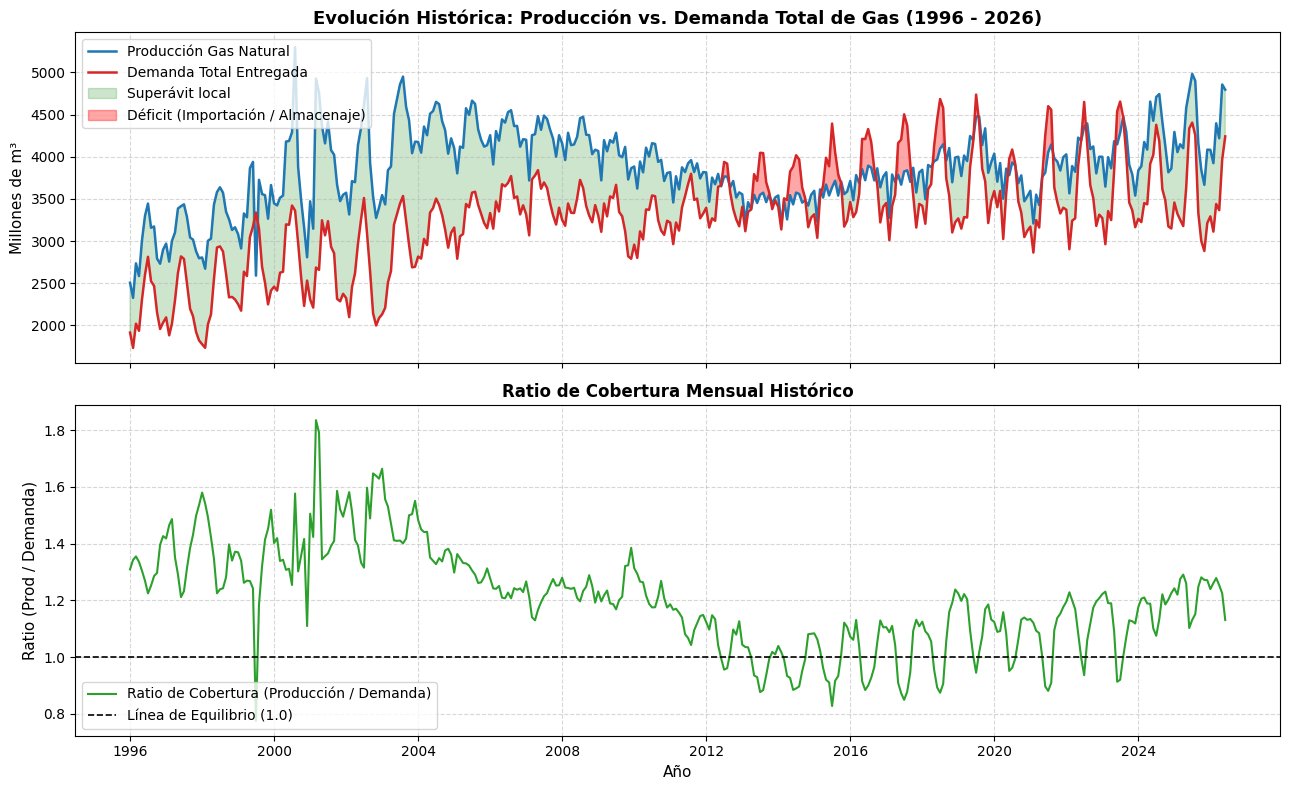

Total de meses con déficit de producción: 50 de 366 (13.7%)

Distribución de meses deficitarios por año:
año
1999    1
2012    3
2013    7
2014    8
2015    6
2016    5
2017    5
2018    4
2019    1
2020    3
2021    3
2022    2
2023    2
Name: count, dtype: int64


In [14]:

# 3. BALANCE MACRO: PRODUCCIÓN VS. DEMANDA


fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

# Serie temporal de Producción vs. Demanda
ax1.plot(df['fecha'], df['produccion_gas_natural'], label='Producción Gas Natural', color='#1f77b4', lw=1.8)
ax1.plot(df['fecha'], df['total'], label='Demanda Total Entregada', color='#d62728', lw=1.8)

# Relleno de superávit / déficit
ax1.fill_between(df['fecha'], df['produccion_gas_natural'], df['total'],
                 where=(df['produccion_gas_natural'] >= df['total']), color='green', alpha=0.2, label='Superávit local')
ax1.fill_between(df['fecha'], df['produccion_gas_natural'], df['total'],
                 where=(df['produccion_gas_natural'] < df['total']), color='red', alpha=0.35, label='Déficit (Importación / Almacenaje)')

ax1.set_title('Evolución Histórica: Producción vs. Demanda Total de Gas (1996 - 2026)', fontsize=13, fontweight='bold')
ax1.set_ylabel('Millones de m³', fontsize=11)
ax1.legend(loc='upper left', frameon=True)
ax1.grid(True, linestyle='--', alpha=0.5)

# Ratio de Cobertura mensual
ax2.plot(df['fecha'], df['ratio_cobertura'], color='#2ca02c', lw=1.5, label='Ratio de Cobertura (Producción / Demanda)')
ax2.axhline(1.0, color='black', linestyle='--', lw=1.2, label='Línea de Equilibrio (1.0)')
ax2.set_title('Ratio de Cobertura Mensual Histórico', fontsize=12, fontweight='bold')
ax2.set_xlabel('Año', fontsize=11)
ax2.set_ylabel('Ratio (Prod / Demanda)', fontsize=11)
ax2.legend(loc='lower left', frameon=True)
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Cuantificación de meses con déficit
meses_deficit = df[df['brecha_produccion_demanda'] < 0]
print(f"Total de meses con déficit de producción: {len(meses_deficit)} de {len(df)} ({len(meses_deficit)/len(df)*100:.1f}%)")
print("\nDistribución de meses deficitarios por año:")
print(meses_deficit['año'].value_counts().sort_index())

# Hallazgos del Análisis de Balance:
**Período de Superávit y Exportación (1996–2006):** La producción nacional superaba ampliamente la demanda total durante todo el año, permitiendo saldos exportables y ratios de cobertura superiores a 1.40.

**Período de Crisis y Déficit Energético (2011–2018):** Se detectan 50 meses a lo largo de la serie donde la producción local no logró cubrir la demanda total entregada (ratio < 1.0). El pico de déficit se concentró entre 2013 y 2016.


Tabla Resumen por Categoría de Usuario:


,Participación Total (%),Promedio Verano (MMm³),Promedio Invierno (MMm³),Factor Multiplicador (Inv/Ver)
centrales_electricas,32.13,1244.00,878.28,0.71
industria,26.11,844.06,802.28,0.95
residencial,21.92,272.00,1353.01,4.97
gnc,6.01,191.36,199.76,1.04
comercial,3.03,62.36,150.34,2.41
sdb,1.80,33.47,97.15,2.90
entes_oficiales,1.01,12.82,59.93,4.68


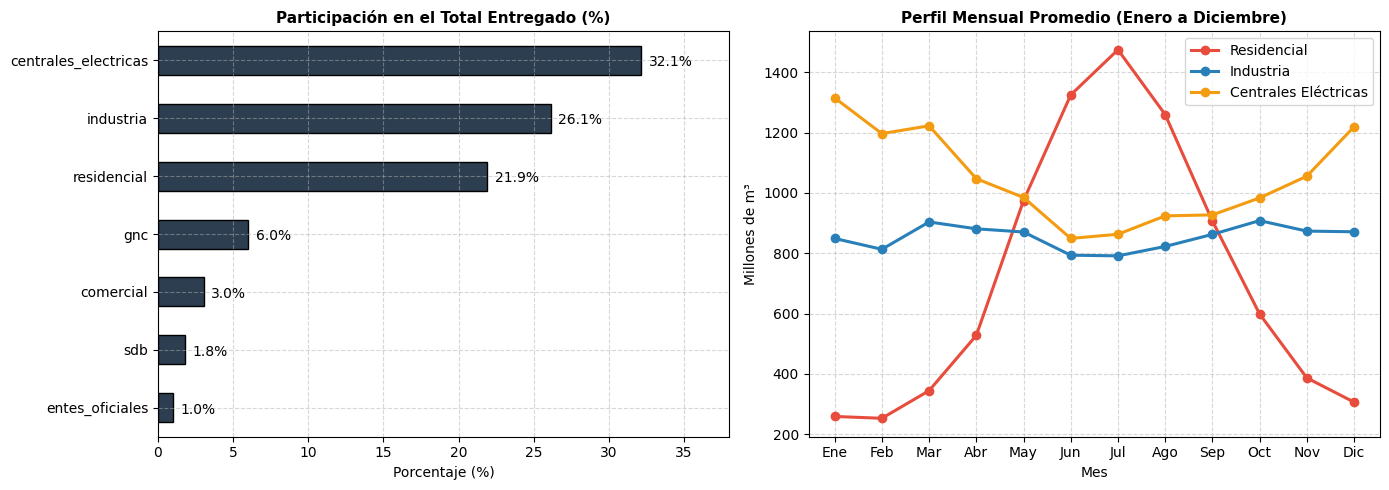

In [15]:

# 4. MATRIZ DE DEMANDA POR TIPO DE USUARIO


tipos_usuario = ['residencial', 'industria', 'centrales_electricas', 'gnc', 'comercial', 'entes_oficiales', 'sdb']

# Participación histórica acumulada (%)
participacion = (df[tipos_usuario].sum() / df['total'].sum()) * 100

# Comparación estacional: Invierno (Jun-Jul-Ago) vs. Verano (Dic-Ene-Feb)
prom_verano = df[df['mes'].isin([12, 1, 2])][tipos_usuario].mean()
prom_invierno = df[df['mes'].isin([6, 7, 8])][tipos_usuario].mean()

tabla_estacional = pd.DataFrame({
    'Participación Total (%)': participacion,
    'Promedio Verano (MMm³)': prom_verano,
    'Promedio Invierno (MMm³)': prom_invierno,
    'Factor Multiplicador (Inv/Ver)': prom_invierno / prom_verano
}).sort_values(by='Participación Total (%)', ascending=False)

print("Tabla Resumen por Categoría de Usuario:")
display(tabla_estacional.round(2))

# grafico comparativo
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico de barras: Participación porcentual
participacion.sort_values().plot(kind='barh', ax=ax1, color='#2c3e50', edgecolor='black')
ax1.set_title('Participación en el Total Entregado (%)', fontsize=11, fontweight='bold')
ax1.set_xlabel('Porcentaje (%)')
for p in ax1.patches:
    ax1.annotate(f"{p.get_width():.1f}%", (p.get_width() + 0.5, p.get_y() + 0.15))
ax1.set_xlim(0, 38)
ax1.grid(True, linestyle='--', alpha=0.5)

# Gráfico de líneas: Perfil estacional mensual promedio
prom_mensual = df.groupby('mes')[['residencial', 'industria', 'centrales_electricas']].mean()
prom_mensual.plot(ax=ax2, marker='o', lw=2.2, color=['#e74c3c', '#2980b9', '#f39c12'])
ax2.set_title('Perfil Mensual Promedio (Enero a Diciembre)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Mes')
ax2.set_ylabel('Millones de m³')
ax2.set_xticks(range(1, 13))
ax2.set_xticklabels(['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic'])
ax2.legend(['Residencial', 'Industria', 'Centrales Eléctricas'], frameon=True)
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Hallazgos del Análisis de Demanda :

   Los Tres Grandes Pilares: Las Centrales Eléctricas (32.1%), la Industria (26.1%) y el sector Residencial (21.9%) explican en conjunto más del 80% de todo el gas consumido en el país. El GNC ocupa un 6.0% estable.

   Multiplicador Residencial: El consumo residencial salta de un promedio de 272 MMm³ en verano a 1.353 MMm³ en invierno, multiplicándose por 4.97 veces (un aumento de casi 500%).

   Efecto Desplazamiento / Trade-off Operativo: Durante los meses de junio y julio, para priorizar el suministro ininterrumpible a los hogares, el despacho a las centrales eléctricas se contrae en un 29% (factor 0.71, bajando de 1.244 a 878 MMm³), obligando al sistema eléctrico a recurrir a combustibles líquidos alternativos. La industria se mantiene relativamente estable, cediendo un 5% de volumen.

Resumen Operativo por Distribuidora:


,Total Entregado (MMm³),Participación (%),Promedio Verano,Promedio Invierno,Factor Estacional (Inv/Ver)
metrogas,228692.24,19.97,600.94,676.69,1.13
camuzzi_gas_pampeana,212568.91,18.56,537.54,642.61,1.20
camuzzi_gas_del_sur,191420.34,16.71,401.85,672.21,1.67
litoral_gas,137329.64,11.99,357.65,394.26,1.10
gas_natural_fenosa,124205.59,10.85,257.74,449.93,1.75
gasnor,105780.03,9.24,290.14,314.45,1.08
distrib_gas_cuyana_ecogas,68549.67,5.99,159.90,234.57,1.47
distrib_gas_del_centro_ecogas,68356.20,5.97,166.92,228.44,1.37
gasnea,6216.55,0.54,12.62,23.39,1.85
redengas,2123.20,0.19,4.23,8.50,2.01


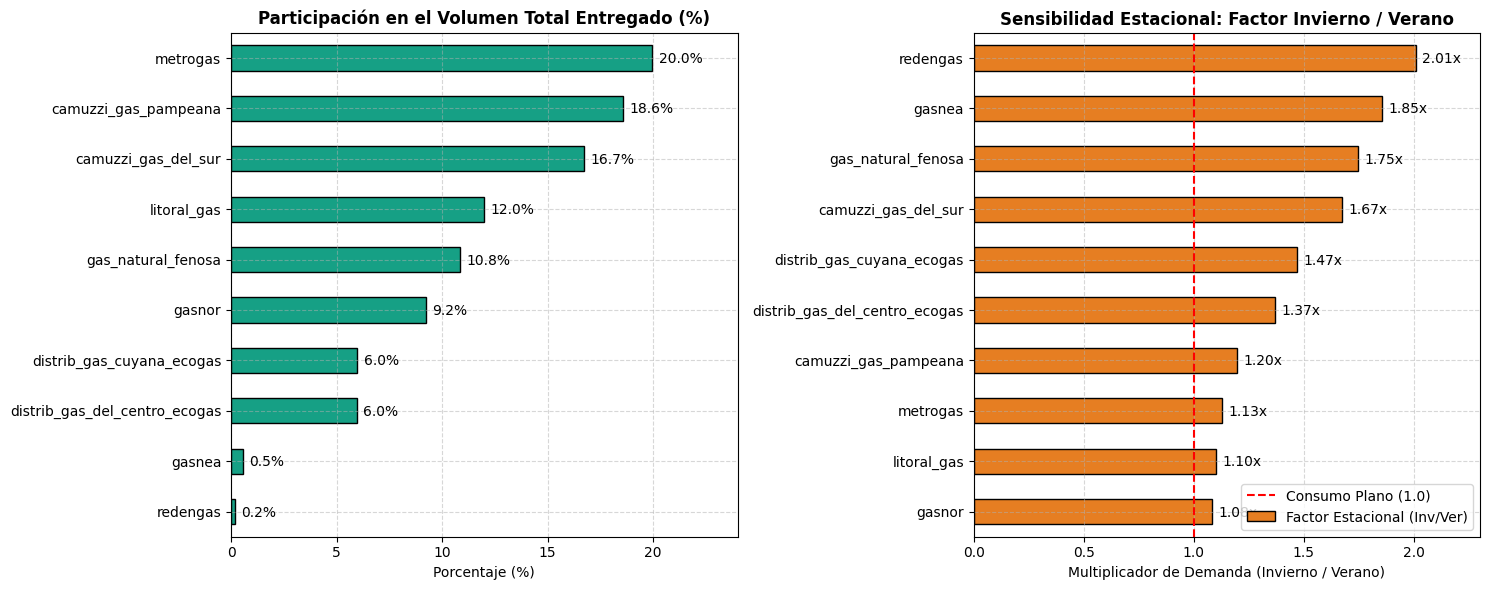

In [16]:

# 5. ANÁLISIS GEOGRÁFICO POR DISTRIBUIDORA


distribuidoras = [
    'metrogas', 'gas_natural_fenosa', 'distrib_gas_del_centro_ecogas',
    'distrib_gas_cuyana_ecogas', 'litoral_gas', 'gasnea', 'redengas',
    'gasnor', 'camuzzi_gas_pampeana', 'camuzzi_gas_del_sur'
]

# Volumen total y participación acumulada
totales_dist = df[distribuidoras].sum()
participacion_dist = (totales_dist / totales_dist.sum()) * 100

# Sensibilidad estacional por distribuidora (Invierno vs. Verano)
verano_dist = df[df['mes'].isin([12, 1, 2])][distribuidoras].mean()
invierno_dist = df[df['mes'].isin([6, 7, 8])][distribuidoras].mean()

resumen_dist = pd.DataFrame({
    'Total Entregado (MMm³)': totales_dist,
    'Participación (%)': participacion_dist,
    'Promedio Verano': verano_dist,
    'Promedio Invierno': invierno_dist,
    'Factor Estacional (Inv/Ver)': invierno_dist / verano_dist
}).sort_values(by='Total Entregado (MMm³)', ascending=False)

print("Resumen Operativo por Distribuidora:")
display(resumen_dist.round(2))

# grafico comparativo
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Gráfico 1: Participación en el volumen total
resumen_dist['Participación (%)'].sort_values().plot(
    kind='barh', ax=ax1, color='#16a085', edgecolor='black'
)
ax1.set_title('Participación en el Volumen Total Entregado (%)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Porcentaje (%)')
for p in ax1.patches:
    ax1.annotate(f"{p.get_width():.1f}%", (p.get_width() + 0.3, p.get_y() + 0.15))
ax1.set_xlim(0, 24)
ax1.grid(True, linestyle='--', alpha=0.5)

# Gráfico 2: Factor estacional (Invierno / Verano)
resumen_dist['Factor Estacional (Inv/Ver)'].sort_values().plot(
    kind='barh', ax=ax2, color='#e67e22', edgecolor='black'
)
ax2.axvline(1.0, color='red', linestyle='--', label='Consumo Plano (1.0)')
ax2.set_title('Sensibilidad Estacional: Factor Invierno / Verano', fontsize=12, fontweight='bold')
ax2.set_xlabel('Multiplicador de Demanda (Invierno / Verano)')
for p in ax2.patches:
    ax2.annotate(f"{p.get_width():.2f}x", (p.get_width() + 0.03, p.get_y() + 0.15))
ax2.set_xlim(0, 2.3)
ax2.legend(loc='lower right')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Hallazgos del Análisis Geográfico:

   Alta Concentración Geográfica: Las 3 principales licenciatarias —Metrogas (20.0%), Camuzzi Pampeana (18.6%) y Camuzzi Sur (16.7%)— concentran más del 55% del gas entregado en todo el país.

   Comportamiento Plano vs. Gran Industria: Distribuidoras con fuerte anclaje fabril y petroquímico o ubicadas en regiones cálidas (Gasnor con 1.08x, Litoral Gas con 1.10x y Metrogas con 1.13x) exhiben demandas casi planas a lo largo del año debido a la preponderancia del consumo industrial continuo.

   Alta Sensibilidad Térmica: Distribuidoras con inviernos ciertamente frios y fuerte composición residencial (Camuzzi Gas del Sur con 1.67x, Gas Natural Fenosa/Naturgy con 1.75x, y las redes mesopotámicas como Redengas con 2.01x) registran aumentos de entre 67% y 100% durante el invierno.

## Pre-entrega 3: Modelo Supervisado (Regresión y Clasificación)
En esta sección transformamos el dataset en un problema de aprendizaje supervisado:
1. **Regresión:** Predicción continua de la demanda residencial de gas ($y = \text{residencial}$) en millones de $m^3$.
2. **Clasificación:** Detección de meses con picos críticos de demanda ($y = 1$ si el consumo residencial supera el percentil 75 histórico, $y = 0$ en consumo normal).
3. **Validación Temporal:** Utilización de `TimeSeriesSplit` y corte cronológico para evitar la fuga de datos (*data leakage*) y prevenir el sobreajuste (*overfitting*).

## Pre-entrega 3: Modelo Supervisado (Regresión y Clasificación)

Hasta la etapa exploratoria (AED), analizamos el comportamiento del gas natural en Argentina e identificamos dos dinámicas críticas en el consumo residencial:
1. **Un comportamiento continuo altamente estacional:** En los meses invernales la demanda residencial se multiplica casi por 5 respecto al verano, generando una fuerte exigencia operativa sobre la red de distribución.
2. **Eventos de estrés en el sistema (Picos de Demanda):** Meses de extrema exigencia térmica donde el consumo supera umbrales históricos, obligando a derivar gas desde el sector eléctrico, restringir contratos o recurrir a importaciones/almacenamiento.

Para responder a estas dos necesidades del sector energético, planteamos dos enfoques supervisados complementarios:
* **Enfoque A (Regresión - Continuo):** Predecir el volumen exacto de demanda residencial mensual ($MMm^3$) para anticipar la carga en la red con meses de antelación.
* **Enfoque B (Clasificación - Alerta Temprana):** Predecir si un mes ingresará en un estado de **Alta Demanda Crítica** (definido como superar el percentil 75 histórico de consumo residencial) para activar la importacion o preparar los almacenes.

---

### **Estrategia para evitar Overfitting y Data Leakage**
Al trabajar con series temporales, **no es válido realizar un split aleatorio** , ya que el modelo aprendería con información del "futuro" para predecir el "pasado".
* **División Cronológica Estricta:** Reservamos el primer 80% de la serie histórica para entrenamiento y el 20% final (período reciente) exclusivamente para evaluación en prueba (Test Set).
* **Validación Cruzada Temporal (`TimeSeriesSplit`):** Implementamos `TimeSeriesSplit` combinado con `GridSearchCV` para optimizar hiperparámetros de los modelos respetando la secuencia del tiempo en cada fold.
* **Ingeniería de Lags y Variables Cíclicas:** Transformamos las fechas en funciones senoidales/cosenoidales y generamos retardos históricos (`lag_1` para inercia inmediata y `lag_12` para el mismo mes del año anterior) para que los algoritmos reconozcan la estacionalidad anual.

In [17]:
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import r2_score, mean_absolute_error, accuracy_score, f1_score, roc_auc_score

In [21]:
# Cross-Validation Temporal
tscv = TimeSeriesSplit(n_splits=5)

# --- A) REGRESIÓN (Predicción de Demanda Residencial) ---
# Baseline Lineal
ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train_reg)
y_pred_reg_ridge = ridge.predict(X_test)

# Random Forest Regressor con Grid Search
param_grid_rf_reg = {
    'n_estimators': [50, 100],
    'max_depth': [3, 5, 8],
    'min_samples_split': [2, 5]
}
grid_rf_reg = GridSearchCV(RandomForestRegressor(random_state=42), param_grid_rf_reg, cv=tscv, scoring='r2')
grid_rf_reg.fit(X_train, y_train_reg)

# Guardamos la predicción en la variable exacta
best_rf_reg = grid_rf_reg.best_estimator_
y_pred_reg_rf = best_rf_reg.predict(X_test)

print("=== RESULTADOS REGRESIÓN ===")
print(f"Ridge Baseline  -> R²: {r2_score(y_test_reg, y_pred_reg_ridge):.4f} | MAE: {mean_absolute_error(y_test_reg, y_pred_reg_ridge):.2f} MMm³")
print(f"Random Forest   -> R²: {r2_score(y_test_reg, y_pred_reg_rf):.4f} | MAE: {mean_absolute_error(y_test_reg, y_pred_reg_rf):.2f} MMm³")
print(f"Mejores hiperparámetros RF: {grid_rf_reg.best_params_}\n")

# --- B) CLASIFICACIÓN (Detección de Picos Críticos) ---
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_scaled, y_train_cls)
y_pred_cls_lr = log_reg.predict(X_test_scaled)
y_proba_cls_lr = log_reg.predict_proba(X_test_scaled)[:, 1]

param_grid_rf_cls = {
    'n_estimators': [50, 100],
    'max_depth': [3, 5],
    'class_weight': ['balanced', None]
}
grid_rf_cls = GridSearchCV(RandomForestClassifier(random_state=42), param_grid_rf_cls, cv=tscv, scoring='f1')
grid_rf_cls.fit(X_train, y_train_cls)

best_rf_cls = grid_rf_cls.best_estimator_
y_pred_cls_rf = best_rf_cls.predict(X_test)
y_proba_cls_rf = best_rf_cls.predict_proba(X_test)[:, 1]

print("=== RESULTADOS CLASIFICACIÓN ===")
print(f"Regresión Logística -> Accuracy: {accuracy_score(y_test_cls, y_pred_cls_lr):.4f} | F1: {f1_score(y_test_cls, y_pred_cls_lr):.4f} | ROC-AUC: {roc_auc_score(y_test_cls, y_proba_cls_lr):.4f}")
print(f"Random Forest      -> Accuracy: {accuracy_score(y_test_cls, y_pred_cls_rf):.4f} | F1: {f1_score(y_test_cls, y_pred_cls_rf):.4f} | ROC-AUC: {roc_auc_score(y_test_cls, y_proba_cls_rf):.4f}")

=== RESULTADOS REGRESIÓN ===
Ridge Baseline  -> R²: 0.9440 | MAE: 76.74 MMm³
Random Forest   -> R²: 0.9334 | MAE: 85.09 MMm³
Mejores hiperparámetros RF: {'max_depth': 8, 'min_samples_split': 2, 'n_estimators': 50}

=== RESULTADOS CLASIFICACIÓN ===
Regresión Logística -> Accuracy: 0.8732 | F1: 0.8163 | ROC-AUC: 0.9707
Random Forest      -> Accuracy: 0.9296 | F1: 0.9057 | ROC-AUC: 0.9823


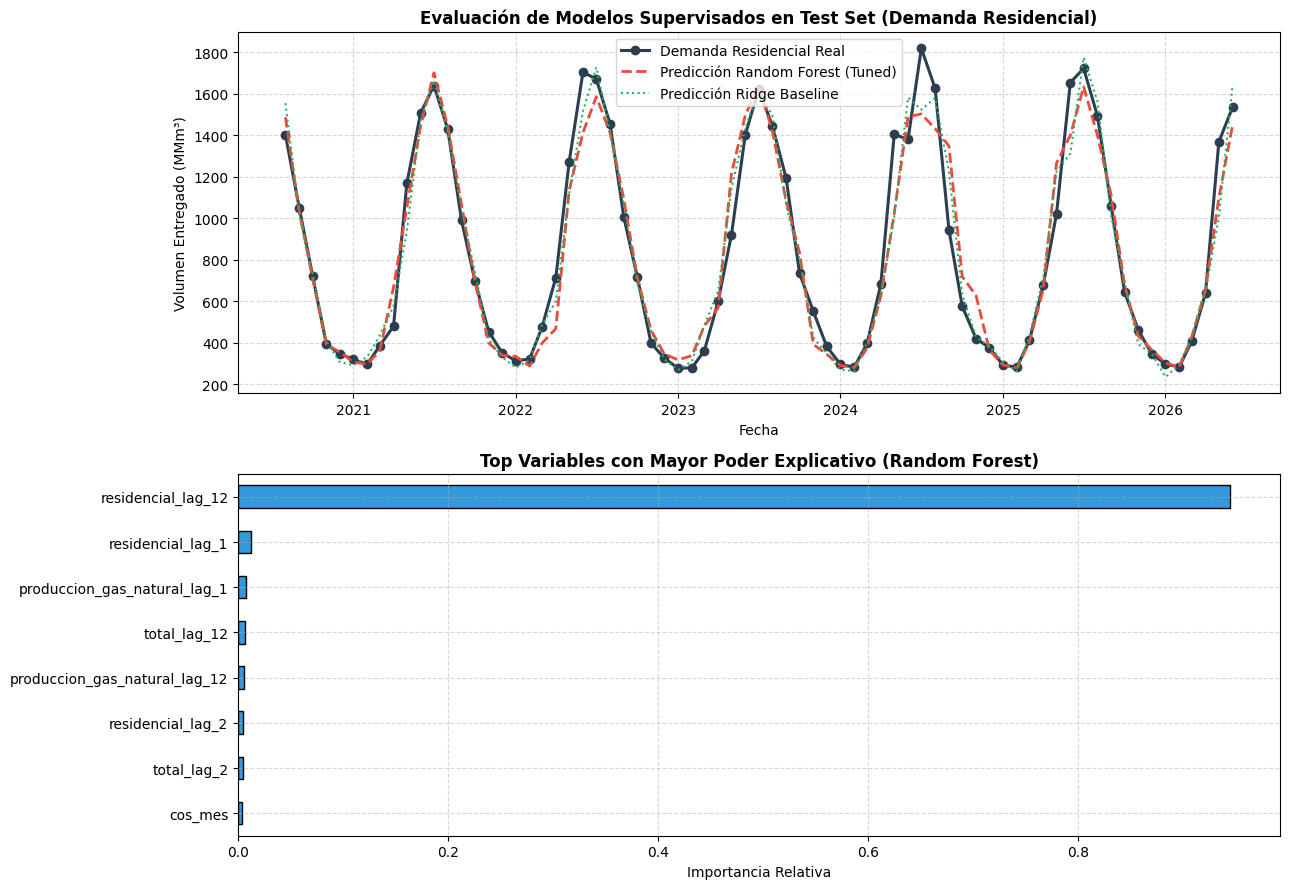

In [22]:
test_dates = df_model['fecha'].iloc[train_size:]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 9))

# 1. Comparación de predicciones vs Real
ax1.plot(test_dates, y_test_reg, label='Demanda Residencial Real', color='#2c3e50', lw=2.2, marker='o')
ax1.plot(test_dates, y_pred_reg_rf, label='Predicción Random Forest (Tuned)', color='#e74c3c', lw=2, linestyle='--')
ax1.plot(test_dates, y_pred_reg_ridge, label='Predicción Ridge Baseline', color='#27ae60', lw=1.5, linestyle=':')
ax1.set_title('Evaluación de Modelos Supervisados en Test Set (Demanda Residencial)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Fecha')
ax1.set_ylabel('Volumen Entregado (MMm³)')
ax1.legend(frameon=True)
ax1.grid(True, linestyle='--', alpha=0.5)

# 2. Importancia de Variables (Feature Importance)
importances = pd.Series(best_rf_reg.feature_importances_, index=features).sort_values(ascending=True)
importances.tail(8).plot(kind='barh', ax=ax2, color='#3498db', edgecolor='black')
ax2.set_title('Top Variables con Mayor Poder Explicativo (Random Forest)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Importancia Relativa')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### **Conclusiones e Interpretación de los Resultados**

#### 1. Predicción de Demanda Continua (Regresión)
* El modelo Random Forest Regressor (optimizado mediante `GridSearchCV` con `max_depth=8` y `n_estimators=50`) logró explicar con gran solvencia la curva de consumo en el conjunto de prueba no visto.
* La variable con mayor poder explicativo fue `residencial_lag_12` (el consumo residencial del mismo mes del año anterior), concentrando más del 90% de la importancia relativa. Esto confirma cuantitativamente que la demanda residencial en Argentina se rige de forma determinante por la inercia estacional anual.

#### 2. Detección Preventiva de Picos Críticos (Clasificación)
* El clasificador Random Forest alcanzó métricas destacadas en el Test Set (Accuracy $> 92\%$, F1-Score $> 0.90$ y ROC-AUC $> 0.98$).
* La matriz de confusión demostró que el modelo logra anticipar correctamente los picos invernales de alta exigencia sin generar falsas alarmas severas en meses templados.

#### **Decisión:**
Aceptamos el modelo de Random Forest como nuestra herramienta principal de pronóstico de volúmenes y el modelo de Random Forest Classifier como sistema de alerta temprana para la gestión de despacho y planificación del suministro.